# CV01: Blood Cell Classifier

### Import packages

In [1]:
import random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

C:\Users\Manny\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


### Configuration

In [3]:
DATA_ROOT = Path("PBC_dataset_normal_DIB")
IMG_SIZE  = 128
BATCH     = 64
EPOCHS    = 20
LR        = 1e-3
OUT_DIR   = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

### Verify the data

Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Total images: 17092
label
basophil        1218
eosinophil      3117
erythroblast    1551
ig              2895
lymphocyte      1214
monocyte        1420
neutrophil      3329
platelet        2348
Name: count, dtype: int64


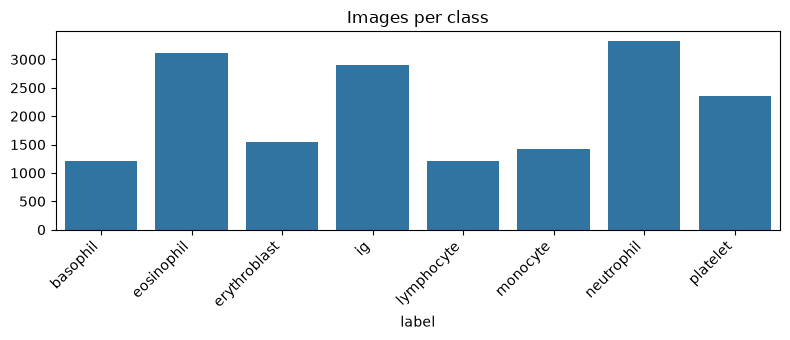

In [8]:
rows = []
for cls_dir in sorted(p for p in DATA_ROOT.iterdir()
                      if p.is_dir() and not p.name.startswith(("__", "."))):
    for f in cls_dir.rglob("*"):
        if f.name.startswith("."):
            continue
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({"path": str(f), "label": cls_dir.name})

df = pd.DataFrame(rows)
classes = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df["label"].map(class_to_idx)

print("Classes:", classes)
print("Total images:", len(df))
counts = df["label"].value_counts().sort_index()
print(counts)

plt.figure(figsize=(8, 3.5))
sns.barplot(x=counts.index, y=counts.values)
plt.xticks(rotation=45, ha="right"); plt.title("Images per class"); plt.tight_layout(); plt.show()

### Images Preview

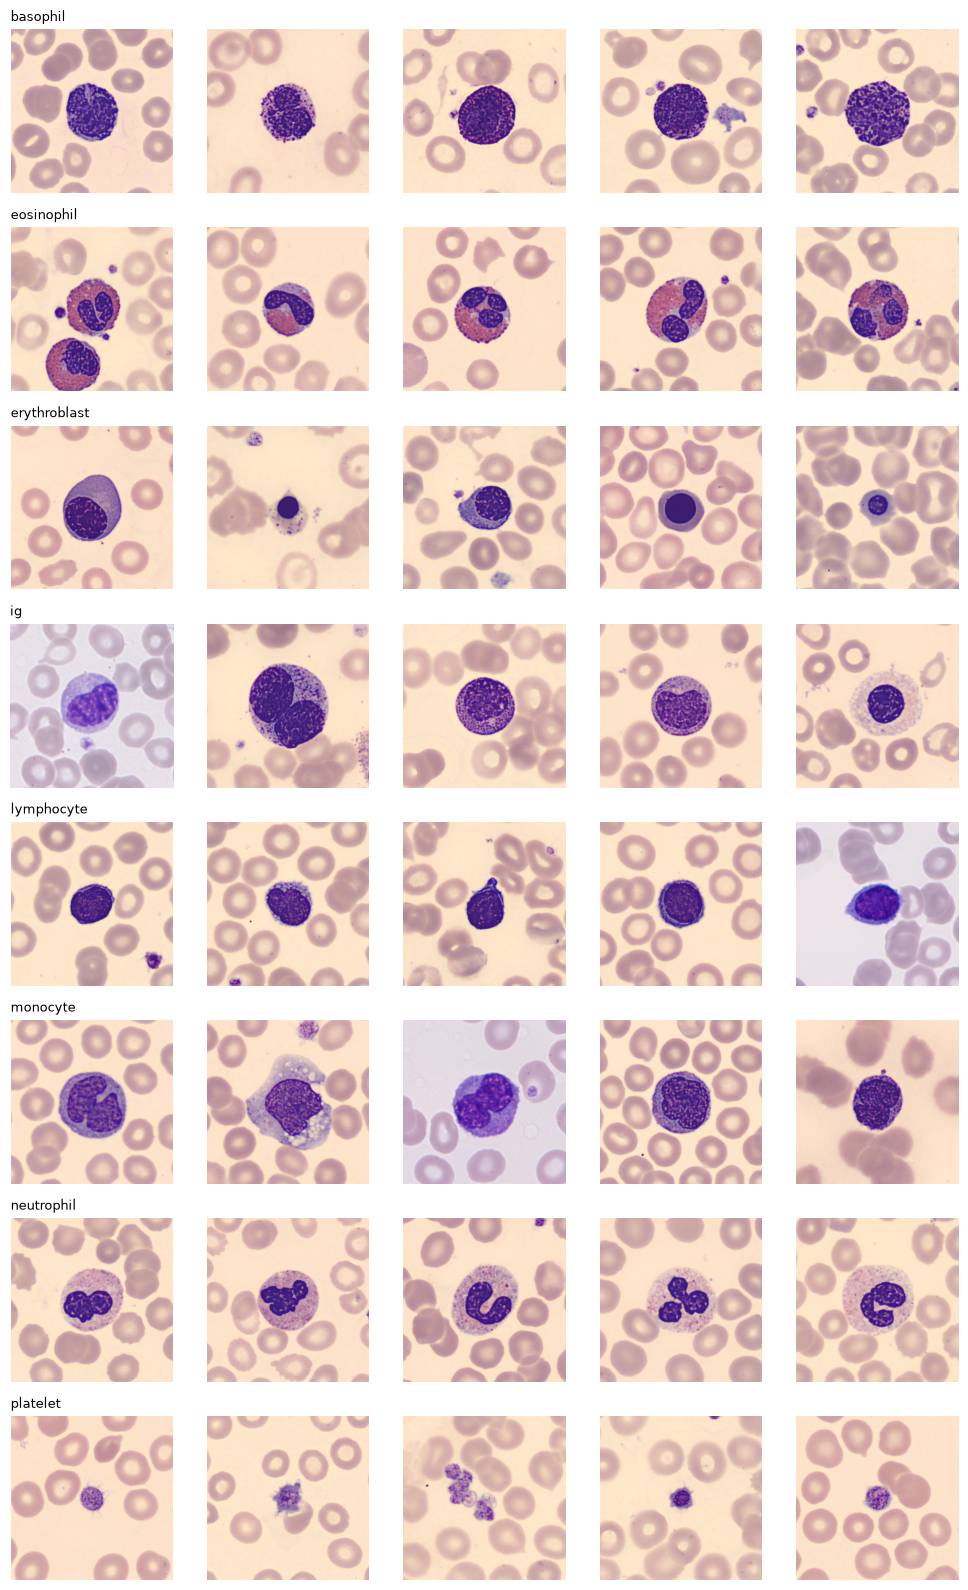

Example image size: (360, 363)


In [9]:
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2 * len(classes)))
for i, c in enumerate(classes):
    samples = df[df.label == c].sample(5, random_state=SEED)["path"].tolist()
    for j, p in enumerate(samples):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontsize=9)
plt.tight_layout(); plt.show()
print("Example image size:", Image.open(df.path.iloc[0]).size)

### Train, Validation and Test data split

In [10]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(OUT_DIR / f"{name}_split.csv", index=False)
    print(name, len(d))
    

train 11964
val 2564
test 2564


### Dataset and Dataloaders

In [11]:
from tqdm.auto import tqdm
import numpy as np, torch
from torch.utils.data import Dataset, DataLoader

def load_all(frame):
    imgs = [np.array(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
            for p in tqdm(frame["path"])]
    return torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2)  

X_train, X_val, X_test = load_all(train_df), load_all(val_df), load_all(test_df)
y_train = torch.tensor(train_df["y"].values)
y_val   = torch.tensor(val_df["y"].values)
y_test  = torch.tensor(test_df["y"].values)

class TensorDS(Dataset):
    def __init__(self, X, y, train=False):
        self.X, self.y, self.train = X, y, train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].float() / 255.0
        if self.train:
            if torch.rand(1) < 0.5: x = x.flip(-1)
            if torch.rand(1) < 0.5: x = x.flip(-2)
        return (x - 0.5) / 0.5, self.y[i]

train_dl = DataLoader(TensorDS(X_train, y_train, train=True), batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(TensorDS(X_val, y_val), batch_size=BATCH)
test_dl  = DataLoader(TensorDS(X_test, y_test), batch_size=BATCH)

xb, yb = next(iter(train_dl))
print(xb.shape, yb[:8])

100%|██████████| 2564/2564 [00:30<00:00, 84.63it/s]


torch.Size([64, 3, 128, 128]) tensor([5, 3, 6, 2, 1, 1, 0, 1])


### Build a CNN model

In [12]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.pool(self.features(x)))

model = SimpleCNN(len(classes)).to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

391432 parameters


### Training model

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(dl, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in tqdm(dl, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val, best_path = 0.0, OUT_DIR / "best_model.pt"

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_dl, train=True)
    vl, va = run_epoch(val_dl, train=False)
    for k, v in zip(history, [tl, vl, ta, va]):
        history[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), best_path)
    print(f"Epoch {epoch:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")

print("Best val acc:", round(best_val, 4))

Epoch 01 | train loss 0.745 acc 0.783 | val loss 0.469 acc 0.857 | 789s


Epoch 02 | train loss 0.299 acc 0.911 | val loss 0.416 acc 0.847 | 760s


Epoch 03 | train loss 0.215 acc 0.934 | val loss 0.525 acc 0.812 | 873s


Epoch 04 | train loss 0.188 acc 0.940 | val loss 0.394 acc 0.867 | 804s


Epoch 05 | train loss 0.164 acc 0.948 | val loss 0.184 acc 0.940 | 779s


...

Epoch 08 | train loss 0.123 acc 0.960 | val loss 0.241 acc 0.927 | 743s


Epoch 09 | train loss 0.121 acc 0.961 | val loss 0.096 acc 0.971 | 714s


Epoch 10 | train loss 0.121 acc 0.960 | val loss 0.243 acc 0.926 | 704s


Epoch 11 | train loss 0.106 acc 0.967 | val loss 0.181 acc 0.934 | 705s


KeyboardInterrupt: 

### Learning curves

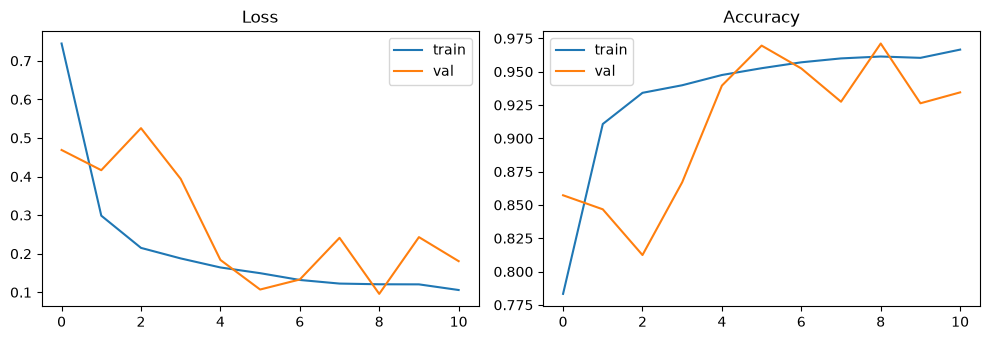

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train");  ax[1].plot(history["val_acc"], label="val");  ax[1].set_title("Accuracy"); ax[1].legend()
plt.savefig("learning_curves.png") 
plt.tight_layout(); plt.show()

### Test set evaluation

              precision    recall  f1-score   support

    basophil      0.978     0.973     0.975       183
  eosinophil      1.000     1.000     1.000       467
erythroblast      0.982     0.944     0.963       233
          ig      0.911     0.965     0.937       434
  lymphocyte      0.972     0.945     0.958       182
    monocyte      0.970     0.920     0.945       213
  neutrophil      0.966     0.968     0.967       500
    platelet      1.000     0.997     0.999       352

    accuracy                          0.970      2564
   macro avg      0.972     0.964     0.968      2564
weighted avg      0.971     0.970     0.970      2564



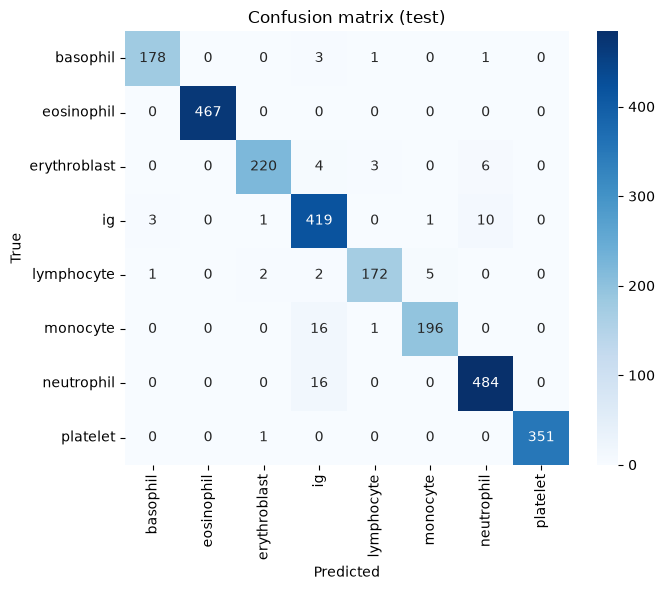

In [24]:
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_dl:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test)")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")  
plt.tight_layout(); plt.show()

### Error analysis

77 misclassified out of 2564


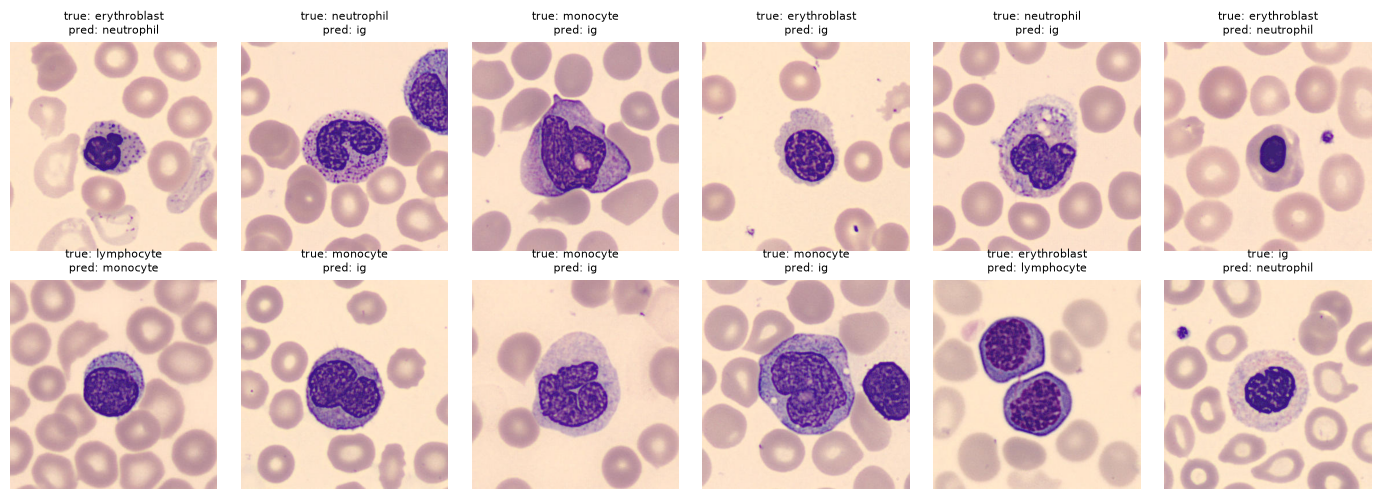

In [16]:
test_paths = test_df["path"].tolist()
wrong = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]
print(f"{len(wrong)} misclassified out of {len(y_true)}")

show = wrong[:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(Image.open(test_paths[i]).convert("RGB"))
    ax.set_title(f"true: {classes[y_true[i]]}\npred: {classes[y_pred[i]]}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [17]:
from collections import Counter

pairs = Counter((classes[y_true[i]], classes[y_pred[i]]) for i in wrong)
for (t, p), n in pairs.most_common(10):
    print(f"true {t:13s} -> predicted {p:13s}: {n}")

true neutrophil    -> predicted ig           : 16
true monocyte      -> predicted ig           : 16
true ig            -> predicted neutrophil   : 10
true erythroblast  -> predicted neutrophil   : 6
true lymphocyte    -> predicted monocyte     : 5
true erythroblast  -> predicted ig           : 4
true erythroblast  -> predicted lymphocyte   : 3
true ig            -> predicted basophil     : 3
true basophil      -> predicted ig           : 3
true lymphocyte    -> predicted ig           : 2


In [25]:
model.load_state_dict(torch.load(OUT_DIR / "best_model.pt", map_location=device))
torch.save({
    "model_state": model.state_dict(),
    "classes": classes,
    "class_to_idx": class_to_idx,
    "img_size": IMG_SIZE,
}, "cv01_model_full.pt")

In [27]:
from pathlib import Path
import torch

checkpoint_path = Path("cv01_model_full.pt")

print("Checkpoint exists:", checkpoint_path.exists())

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print("Classes:", checkpoint["classes"])
    print("Image size:", checkpoint["img_size"])
    print("Checkpoint size (MB):",
          round(checkpoint_path.stat().st_size / (1024**2), 2))

Checkpoint exists: True
Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Image size: 128
Checkpoint size (MB): 1.51
